# Structural Analysis Toolkit (SAT)

## If anything goes wrong:  
### Restart the kernel using the &#8635; button at the top of this notebook, or from the menu: `Kernel > Restart Kernel...`

## **During the tutorials just run through the cells using the given example files and code. Later you will use your own CAD drawing and edit the code to solve your own structural optimisation problem.**

### Flowchart for this Notebook:

![](flow_1.png)

## Loading the external files

### Run the cell below which loads it into Python and creates lists of `Node` and `Member` objects.

In [1]:
# ===================================================
# Ensure the input filenames below match uploded files
# ===================================================
from import_functions import extract_structure_from_dxf

# input files
INPUT_DXF = "first_truss.dxf"

# import data and create lists of nodes and members, each with its own ID, name, properties, etc...
nodes, members = extract_structure_from_dxf(INPUT_DXF, units='mm', tol=0.1)

* For info on the `extract_structure_from_dxf` function, run the cell below:

In [2]:
help(extract_structure_from_dxf)

Help on function extract_structure_from_dxf in module import_functions:

extract_structure_from_dxf(file_path, units='mm', tol=0.001)
    Import a DXF line drawing and convert it into a structural model.

    The function:
    1. Reads LINE entities from the DXF.
    2. Finds all line intersections.
    3. Creates nodes at endpoints and intersections.
    4. Merges nearby nodes within a tolerance.
    5. Splits members wherever a node lies along a line.
    6. Creates Node and Member objects.
    7. Builds nodal connectivity information.

    Parameters
    ----------
    file_path : str
        Path to the DXF file.

    units : str
        Either 'mm' or 'm'. If 'mm', coordinates are converted to metres.

    tol : float
        Distance tolerance used for node merging and geometric matching.

    Returns
    -------
    nodes : dict
        Dictionary of Node objects indexed by node label.

    members : dict
        Dictionary of Member objects indexed by member name.



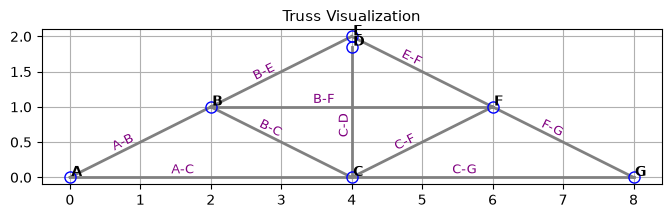

In [3]:
##########################################
# Visualisation of the imported structure
##########################################
from visualisation import visualize_truss

# show the imported structure
fig,ax = visualize_truss(nodes, members, textscale=1, show_node_labels=True, show_member_labels=True)

* **Make sure all of the members and joints have unique labels,**
    * if not you need to edit your CAD drawing to make it more accurate and re-import it.
    * In this case the apex (at `D` and `E`) is not joined up.
        1. Open the `first_truss.dxf` file in AutoCAD and correct this inaccuracy.
        2. Save the truss as `structure.dxf` 
        3. Re-import the structure in the cell below using the `extract_structure_from_dxf` function then plot it using the `visualize_truss` function to check the accuracy:

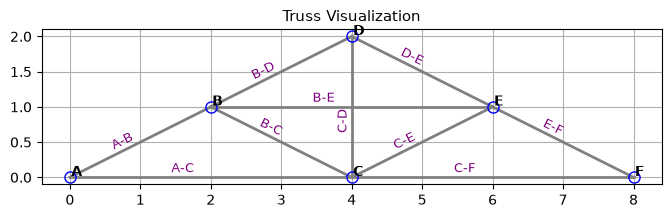

In [4]:
############################################
### MODEL ANSWER - REMOVE BEFORE RELEASE ###
############################################

nodes, members = extract_structure_from_dxf('structure.dxf', units='mm', tol=0.1)
fig,ax = visualize_truss(nodes, members, textscale=1, show_node_labels=True, show_member_labels=True)

* We can now inspect the nodes (and members) created:

In [5]:
# list the nodes
print("nodes =", nodes)
print()
print("members =", members)

nodes = {'A': Node(A, (0.0, 0.0, 0.0)), 'B': Node(B, (2.0, 1.0, 0.0)), 'C': Node(C, (4.0, 0.0, 0.0)), 'D': Node(D, (4.0, 2.0, 0.0)), 'E': Node(E, (6.0, 1.0, 0.0)), 'F': Node(F, (8.0, 0.0, 0.0))}

members = {'A-C': Member(A-C), 'C-F': Member(C-F), 'A-B': Member(A-B), 'B-C': Member(B-C), 'C-E': Member(C-E), 'E-F': Member(E-F), 'B-D': Member(B-D), 'D-E': Member(D-E), 'C-D': Member(C-D), 'B-E': Member(B-E)}


* Let's extract a single node from the `nodes` dictionary and inspect it using the `help()` function:

* A `Member` _object_ has various properties that can be accessed using the DOT syntax: `OBJECT.PROPERTY` 

In [6]:
m = members['A-B']

membername = m.name
membervec = m.vector
memberlength = m.length

print(membername, membervec, memberlength)

A-B (2.0, 1.0) 2.23606797749979


* To see the full documentation on the properties of a member, run the help function below: 

In [7]:
help(m)

Help on Member in module structural_classes object:

class Member(builtins.object)
 |  Member(id, start_node, end_node)
 |
 |  Structural member connecting two nodes.
 |
 |  A member stores its end nodes, applied loads,
 |  material properties and analysis results.
 |
 |  Parameters
 |  ----------
 |  id : int
 |      Unique member number.
 |
 |  start_node : Node
 |      Node at one end of the member.
 |
 |  end_node : Node
 |      Node at the other end of the member.
 |
 |  Attributes
 |  ----------
 |  name : str
 |      Member label (e.g. A-B).
 |
 |  force : float
 |      Axial force in the member.
 |
 |  stress : float
 |      Member stress.
 |
 |  utilisation : float
 |      Utilisation ratio.
 |
 |  properties : dict
 |      Member properties such as area or stiffness.
 |
 |  moments : dict
 |      Bending moment results.
 |
 |  Methods defined here:
 |
 |  __init__(self, id, start_node, end_node)
 |      Initialize self.  See help(type(self)) for accurate signature.
 |
 |  __r

* Similarly, we can investigate individual nodes
* Here we list some properties of each of the nodes in a loop:

In [8]:
n = nodes['B']
for n in nodes.values():
    print(n.label, n.coords, n.connectivity)

A (0.0, 0.0, 0.0) ['C', 'B']
B (2.0, 1.0, 0.0) ['A', 'C', 'D', 'E']
C (4.0, 0.0, 0.0) ['A', 'F', 'B', 'E', 'D']
D (4.0, 2.0, 0.0) ['B', 'E', 'C']
E (6.0, 1.0, 0.0) ['C', 'F', 'D', 'B']
F (8.0, 0.0, 0.0) ['C', 'E']


* Compare this information to the structral visualisation above.
* The help function shows the full information about the `Node` _class_:

In [9]:
help(n)

Help on Node in module structural_classes object:

class Node(builtins.object)
 |  Node(id, coords, label=None, condition='Pinned')
 |
 |  Structural node (joint).
 |
 |  A node stores its coordinates, support condition,
 |  applied loads, support reactions and connections
 |  to other nodes.
 |
 |  Parameters
 |  ----------
 |  id : int
 |      Unique node number.
 |
 |  coords : tuple
 |      Coordinates in the form (x, y, z).
 |
 |  label : str, optional
 |      Node name. If not supplied, a label is
 |      generated automatically.
 |
 |  condition : str, optional
 |      Support condition such as:
 |      - "Pinned"
 |      - "Fixed"
 |      - "Reaction_Pinned"
 |      - "Reaction_Roller_H"
 |
 |  Attributes
 |  ----------
 |  label : str
 |      Node label.
 |
 |  coords : tuple
 |      Node coordinates.
 |
 |  F_x, F_y : float
 |      Applied nodal loads.
 |
 |  R_x, R_y : float
 |      Support reactions.
 |
 |  connectivity : list
 |      Labels of connected nodes.
 |
 |  Metho

### The dictionary in the cell below is used to to assign different joint types

* Try editing and re-running it to see the effect it has

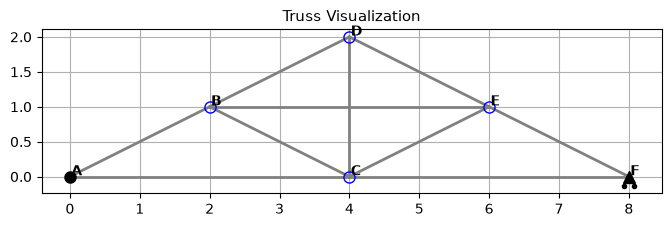

In [10]:
##########################################
# Edit this to assign conditions to joints
##########################################

# comma-separated lists of node-labels as dictionary values 
# default value is "Pinned"
JOINT_CONDITIONS = {
"Pinned":            [],	     # Internal pin (free rotation, no support)	    ○	Blue
"Fixed":             [],         # Internal fixed joint (rigid)	                □	~Blue
"Reaction_Fixed":    [],	     # External fixed support	                    ■	Black
"Reaction_Pinned":   ['A'],      # External pinned support	                    ●	Black
"Reaction_Roller_H": ['F'],      # Horizontal roller (restrained vertically)	▲	Black
"Reaction_Roller_V": []	         # Vertical roller (restrained horizontally)	▼	Black
}

#########################
# Assign point conditions 
#########################
from struct_prop_funcs import apply_joint_conditions

# assign joint conditions
apply_joint_conditions(nodes, JOINT_CONDITIONS)

fig, ax = visualize_truss(nodes, members, show_node_labels=True)

The following joint conditions are available:

| Type                | Description                               | Marker | Colour |
| ------------------- | ----------------------------------------- | ------ | ----- |
| `Pinned`            | Internal pin (free rotation, no support)  | ○      | Blue  |
| `Fixed`             | Internal fixed joint (rigid)              | □      | Blue  |
| `Reaction_Fixed`    | External fixed support                    | ■      | Black |
| `Reaction_Pinned`   | External pinned support                   | ●      | Black |
| `Reaction_Roller_H` | Horizontal roller (restrained vertically) | ▲      | Black |
| `Reaction_Roller_V` | Vertical roller (restrained horizontally) | ▼      | Black |

Note on terminology:  
**Pinned:** Internal joint only  
**Reaction_Pinned:** External support providing reactions

## Next follows an example of what you can do with your structural objects...

### Check if determinate

We need to check if the truss is determinate. This consistes of the steps: 

**[Import Structural Model] → [Count Joints, Members and Reactions] → [Check Overall Determinacy] →
[Check Support Conditions] → [Check External Stability] → [Check Local Stability] → [Report Findings]**

![](det-flow.png)

## Exercise: How does the code assess a truss?

### Task 1

Study the flowchart (<a href="./det-flow.png">Open full-size image</a>).

For each step:

- What engineering question is being asked?
- What information is needed?
- What conclusion is reached?

---

### Task 2

Compare the flowchart with the Python code.

Match each flowchart step to the section of code that performs it.

| Flowchart Step | Code Section |
|---------------|-------------|
| Count joints, members and reactions | |
| Check determinacy | |
| Check supports | |
| Check external stability | |
| Check local mechanisms | |

---

### Task 3

Comment the code.

Your comments should explain:

- What the code is calculating.
- Why the calculation is useful.
- What engineering conclusion can be drawn.

---
* Python comments:
```python
# this is a comment, it is for your information and ignored by python when the programme runs
```

In [11]:
n_nodes = len(nodes)
n_members = len(members)
n_reactions = sum(n.unknowns for n in nodes.values())
determinacy = 2 * n_nodes - (n_members + n_reactions)

print("\n### Truss Diagnostics ###")
print(f"Number of nodes (joints):       {n_nodes}")
print(f"Number of members:             {n_members}")
print(f"Number of unknown reactions:   {n_reactions}")
print(f"Determinant (2j - (m+r)):     {determinacy}")

if determinacy == 0:
    status = "=> Statically determinate (truss)"
elif determinacy > 0:
    status = "!!! Unstable mechanism possible (truss)"
else:
    status = "!!! Statically indeterminate (truss)"
print(f"Status: {status}\n")

print("Supports and unknown reaction components:")
problem_supports = []
for label, n in nodes.items():
    cond = n.condition
    if n.unknowns > 0:
        print(f"  Node {label:>3}: {cond:20} -> {n.unknowns} unknown reaction(s)")
        if n.unknowns > 2:
            problem_supports.append((label, cond, "Too many unknown reactions → may cause indeterminacy"))

if problem_supports:
    print("\nProblematic Supports:")
    for label, cond, issue in problem_supports:
        print(f"  Node {label:>3}: {cond:20} -> {issue}")
else:
    print("\nNo problematic supports detected.")

print("\nTotal unknown reaction check:")
if n_reactions > 3:
    print(f"!!! Total unknown reactions = {n_reactions} > 3 --> system is statically indeterminate for rigid 2D body")
elif n_reactions < 3:
    print(f"!!! Total unknown reactions = {n_reactions} < 3 --> system may be unstable (mechanism possible)")
else:
    print(f"=> Total unknown reactions = {n_reactions} --> externally determinate")

potential_mech_nodes = []
for label, n in nodes.items():
    if n.unknowns == 0 and len(n.connectivity) < 2:
        print(f"Warning: Node {label} has {len(n.connectivity)} connected member(s)")
    cond = n.condition
    if n.unknowns > 0:
        continue  
    n_conn = len(n.connectivity) 
    if n_conn < 2:
        potential_mech_nodes.append((label, n_conn, "Too few connected members --> possible local mechanism"))

if potential_mech_nodes:
    print("\nPotential Mechanism Nodes:")
    for label, n_conn, issue in potential_mech_nodes:
        print(f"  Node {label}: {n_conn} member(s) connected -> {issue}")
else:
    print("\nNo obvious local mechanism nodes detected.")



### Truss Diagnostics ###
Number of nodes (joints):       6
Number of members:             10
Number of unknown reactions:   3
Determinant (2j - (m+r)):     -1
Status: !!! Statically indeterminate (truss)

Supports and unknown reaction components:
  Node   A: Reaction_Pinned      -> 2 unknown reaction(s)
  Node   F: Reaction_Roller_H    -> 1 unknown reaction(s)

No problematic supports detected.

Total unknown reaction check:
=> Total unknown reactions = 3 --> externally determinate

No obvious local mechanism nodes detected.


* You could edit the structure in AutoCAD and remove a member to make it determinate.

However, the following cell shows how to define a new function for removing a member automatically:

In [12]:
def remove_member(nodes, members, member_name):
    # remove the member from the dictionary of members
    m = members.pop(member_name)

    # get the node labels for the start and end of the deleted member
    n1 = m.start_node.label
    n2 = m.end_node.label

    # update node connectivity
    nodes[n1].connectivity.remove(n2)
    nodes[n2].connectivity.remove(n1)

* remind yourself how to define functions using parameters and the `def` keyword.

The next cell shows using the new function and visualising:

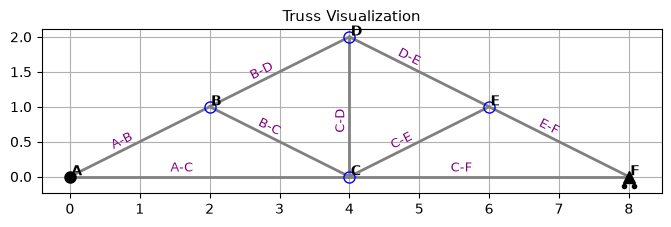

In [13]:
remove_member(nodes, members, "B-E")
fig,ax = visualize_truss(nodes, members, textscale=1, show_node_labels=True, show_member_labels=True)

#### **Task:** define a new function called `check_determinacy` and put the entire determinacy checking code into a function code block so it can be re-used as a function:

In [14]:
# define a function name here
    # the code for the
    # determinacy check
    # all goes here

In [15]:
###############################
###
### MODEL ANSWER 
###
### REMOVE BEFORE PUBLISHING
###
###############################

def check_determinacy(nodes, members):
    n_nodes = len(nodes)
    n_members = len(members)
    n_reactions = sum(n.unknowns for n in nodes.values())
    determinacy = 2 * n_nodes - (n_members + n_reactions)
    
    print("\n### Truss Diagnostics ###")
    print(f"Number of nodes (joints):       {n_nodes}")
    print(f"Number of members:             {n_members}")
    print(f"Number of unknown reactions:   {n_reactions}")
    print(f"Determinant (2j - (m+r)):     {determinacy}")
    
    if determinacy == 0:
        status = "=> Statically determinate (truss)"
    elif determinacy > 0:
        status = "!!! Unstable mechanism possible (truss)"
    else:
        status = "!!! Statically indeterminate (truss)"
    print(f"Status: {status}\n")
    
    print("Supports and unknown reaction components:")
    problem_supports = []
    for label, n in nodes.items():
        cond = n.condition
        if n.unknowns > 0:
            print(f"  Node {label:>3}: {cond:20} -> {n.unknowns} unknown reaction(s)")
            if n.unknowns > 2:
                problem_supports.append((label, cond, "Too many unknown reactions → may cause indeterminacy"))
    
    if problem_supports:
        print("\nProblematic Supports:")
        for label, cond, issue in problem_supports:
            print(f"  Node {label:>3}: {cond:20} -> {issue}")
    else:
        print("\nNo problematic supports detected.")
    
    print("\nTotal unknown reaction check:")
    if n_reactions > 3:
        print(f"!!! Total unknown reactions = {n_reactions} > 3 --> system is statically indeterminate for rigid 2D body")
    elif n_reactions < 3:
        print(f"!!! Total unknown reactions = {n_reactions} < 3 --> system may be unstable (mechanism possible)")
    else:
        print(f"=> Total unknown reactions = {n_reactions} --> externally determinate")
    
    potential_mech_nodes = []
    for label, n in nodes.items():
        if n.unknowns == 0 and len(n.connectivity) < 2:
            print(f"Warning: Node {label} has {len(n.connectivity)} connected member(s)")
        cond = n.condition
        if n.unknowns > 0:
            continue  
        n_conn = len(n.connectivity) 
        if n_conn < 2:
            potential_mech_nodes.append((label, n_conn, "Too few connected members --> possible local mechanism"))
    
    if potential_mech_nodes:
        print("\nPotential Mechanism Nodes:")
        for label, n_conn, issue in potential_mech_nodes:
            print(f"  Node {label}: {n_conn} member(s) connected -> {issue}")
    else:
        print("\nNo obvious local mechanism nodes detected.")


* Predict whether the structure is determinate, indeterminate or unstable before running the code.
* Now run the cell below to _call_ your function on the updated nodes and members:

In [16]:
check_determinacy(nodes, members)


### Truss Diagnostics ###
Number of nodes (joints):       6
Number of members:             9
Number of unknown reactions:   3
Determinant (2j - (m+r)):     0
Status: => Statically determinate (truss)

Supports and unknown reaction components:
  Node   A: Reaction_Pinned      -> 2 unknown reaction(s)
  Node   F: Reaction_Roller_H    -> 1 unknown reaction(s)

No problematic supports detected.

Total unknown reaction check:
=> Total unknown reactions = 3 --> externally determinate

No obvious local mechanism nodes detected.


## Finally: Save your new structure back to a DXF to import into AutoCAD

In [17]:
from import_functions import export_to_dxf

OUTPUT_DXF = "new_structure.dxf"

# save new structure
export_to_dxf(nodes, members, OUTPUT_DXF, units='mm')

=> DXF exported to new_structure.dxf
